# Introduction
## The paper, https://www.pnas.org/doi/full/10.1073/pnas.2200890119, titled
### "Wavier Jet Streams driven by zonally asymettric thermal forcing"
### describes differential equations that cause a response to a forcing not radially
### symmetric about the poles.

### Equations

### Numerical Methods

# TEST CODE BELOW

### Necessary Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Updating Parameters so Plots are Bigger and Easier to Read
plt.rcParams.update({
    "figure.dpi": 140,
    "font.size": 10.5,
    "axes.titlesize": 11.5,
    "axes.labelsize": 10.5,
    "legend.fontsize": 9.5,
})

### Designing our Demonstrative Schematic

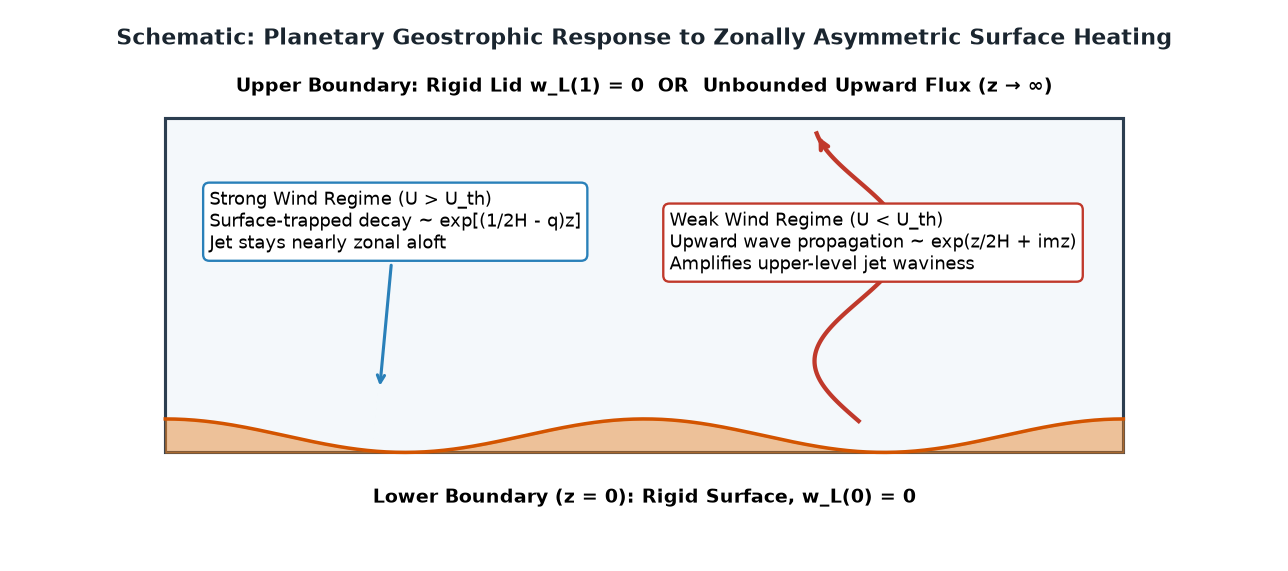

In [2]:
# Schematic diagram illustrating the physical domain, forcing, BCs, and U_th transition
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.set_xlim(0, 10)
ax.set_ylim(0, 5.2)
ax.axis("off")

# Atmosphere domain box
domain = patches.Rectangle((1.2, 1.0), 7.6, 3.2, linewidth=1.6, edgecolor="#2c3e50", facecolor="#f4f8fb")
ax.add_patch(domain)

# Surface thermal forcing wave along z = 0
x_s = np.linspace(1.2, 8.8, 300)
z_wave = 1.0 + 0.32 * (0.5 + 0.5 * np.cos(2 * np.pi * (x_s - 1.2) / 3.8))
ax.fill_between(x_s, 1.0, z_wave, color="#e67e22", alpha=0.45, label="Surface Thermal Forcing Q₀ cos(2x) exp(-k_s z)")
ax.plot(x_s, z_wave, color="#d35400", lw=1.8)

# Left side: U > U_th (surface trapped)
ax.annotate(
    "Strong Wind Regime (U > U_th)\nSurface-trapped decay ~ exp[(1/2H - q)z]\nJet stays nearly zonal aloft",
    xy=(2.9, 1.6), xytext=(1.55, 2.95),
    arrowprops=dict(arrowstyle="->", color="#2980b9", lw=1.6),
    fontsize=9.2, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#2980b9", lw=1.2)
)

# Right side: U < U_th (upward propagating wave)
z_prop = np.linspace(1.3, 4.05, 120)
x_prop = 6.7 - 0.35 * np.sin(2.4 * np.pi * (z_prop - 1.3) / 2.75)
ax.plot(x_prop, z_prop, color="#c0392b", lw=2.2)
ax.annotate("", xy=(x_prop[-1], z_prop[-1]), xytext=(x_prop[-6], z_prop[-6]),
            arrowprops=dict(arrowstyle="->", color="#c0392b", lw=2.2))
ax.text(5.2, 2.75, "Weak Wind Regime (U < U_th)\nUpward wave propagation ~ exp(z/2H + imz)\nAmplifies upper-level jet waviness",
        fontsize=9.2, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#c0392b", lw=1.2))

# Boundary labels
ax.text(5.0, 0.52, "Lower Boundary (z = 0): Rigid Surface, w_L(0) = 0", ha="center", fontsize=10, fontweight="bold")
ax.text(5.0, 4.45, "Upper Boundary: Rigid Lid w_L(1) = 0  OR  Unbounded Upward Flux (z → ∞)",
        ha="center", fontsize=10, fontweight="bold")
ax.text(5.0, 4.9, "Schematic: Planetary Geostrophic Response to Zonally Asymmetric Surface Heating",
        ha="center", fontsize=11.5, fontweight="bold", color="#1a252f")

plt.tight_layout()
plt.show()

### Actually Sitting Down and Making the Physical Parameters for our Model
#### Parameter Functions We Can Call Upon

In [3]:
# Pack up the paper's parameters and compute the threshold wind U_th while we're at it
def make_params(U=1.5, beta_L=1.0, S=1.0, H=0.5, k_s=2.0, Q0=0.05, wavenumber=2):
    ## Return physical parameters matching Figs. 1-4 of Moon et al. (2022).
    U_th = 4.0 * (H**2) * beta_L * S
    return {
        "U": float(U),
        "beta_L": float(beta_L),
        "S": float(S),
        "H": float(H),
        "k_s": float(k_s),
        "Q0": float(Q0),
        "k": int(wavenumber),
        "U_th": float(U_th),
    }

In [4]:
# Cosine heating and its handy antiderivative so we don't integrate by hand every time
def forcing_xz(x, p):
    ## Zonal thermal forcing profile G(x) = cos(k*x) and antiderivative F(x) = sin(k*x)/k.
    k = p["k"]
    return np.cos(k * x), np.sin(k * x) / k

#### Algebraic Solvers

In [5]:
# Exact rigid-lid solution—tedious algebra already done so we don't have to suffer through it every time
def analytical_rigid_lid(x, z, p):
    ## Exact closed-form analytical solution for rigid-lid BCs w_L(0) = w_L(1) = 0
    ## (Moon et al. 2022, Sections A.1 and A.2, Eqs. 13-14 and Eqs. 21-22).
    X, Z = np.meshgrid(x, z, indexing="ij")
    G, F = forcing_xz(x, p)
    U, beta_L, S, H, k_s, Q0 = p["U"], p["beta_L"], p["S"], p["H"], p["k_s"], p["Q0"]
    denom = U * (k_s**2 + k_s / H) + beta_L * S
    disc = 1.0 / (4.0 * H**2) - (beta_L * S) / U

    if disc > 0:
        ### Supercritical branch
        q = np.sqrt(disc)
        c_denom = 2.0 * np.exp(1.0 / (2.0 * H)) * np.sinh(q)
        term1 = -((np.exp(1.0 / (2.0 * H) - q) - np.exp(-k_s)) / c_denom) * np.exp((1.0 / (2.0 * H) + q) * Z)
        term2 = ((np.exp(1.0 / (2.0 * H) + q) - np.exp(-k_s)) / c_denom) * np.exp((1.0 / (2.0 * H) - q) * Z)
        term3 = -(k_s + 1.0 / H) * np.exp(-k_s * Z)
        phi_L = (Q0 * F[:, None] / denom) * (term1 + term2 + term3)

        w_term1 = ((np.exp(1.0 / (2.0 * H) - q) - np.exp(-k_s)) / c_denom) * np.exp((1.0 / (2.0 * H) + q) * Z)
        w_term2 = -((np.exp(1.0 / (2.0 * H) + q) - np.exp(-k_s)) / c_denom) * np.exp((1.0 / (2.0 * H) - q) * Z)
        w_L = (beta_L * Q0 * G[:, None] / denom) * (w_term1 + w_term2 + np.exp(-k_s * Z))
    else:
        ### Subcritical branch
        m = np.sqrt(-disc)
        psi_phase = np.arctan2(1.0 / (2.0 * H), m)
        amp_fac = np.sqrt(beta_L * S / U)
        osc_phi = np.exp(Z / (2.0 * H)) * (
            -np.sin(m * Z - m - psi_phase) + np.exp(-(k_s + 1.0 / (2.0 * H))) * np.sin(m * Z - psi_phase)
        ) / np.sin(m)
        phi_L = (Q0 * F[:, None] / denom) * (amp_fac * osc_phi - (k_s + 1.0 / H) * np.exp(-k_s * Z))

        osc_w = np.exp(Z / (2.0 * H)) * (
            np.sin(m * Z - m) - np.exp(-(k_s + 1.0 / (2.0 * H))) * np.sin(m * Z)
        ) / np.sin(m)
        w_L = (beta_L * Q0 * G[:, None] / denom) * (osc_w + np.exp(-k_s * Z))

    ## Numerical x-derivative for meridional velocity v_L
    if len(x) > 1:
        dx = x[1] - x[0]
        v_L = np.gradient(phi_L, dx, axis=0)
    else:
        v_L = np.zeros_like(phi_L)
    return X, Z, phi_L, w_L, v_L

In [6]:
# Same idea up to z -> inf, assuming the atmosphere doesn't run out of room
def analytical_unbounded(x, z, p):
    ## Exact closed-form analytical solution for unbounded upper domain z -> inf
    ## (Moon et al. 2022, Sections B.1 and B.2, Eqs. 26-27 and Eqs. 30-31).
    X, Z = np.meshgrid(x, z, indexing="ij")
    G, F = forcing_xz(x, p)
    U, beta_L, S, H, k_s, Q0 = p["U"], p["beta_L"], p["S"], p["H"], p["k_s"], p["Q0"]
    denom = U * (k_s**2 + k_s / H) + beta_L * S
    disc = 1.0 / (4.0 * H**2) - (beta_L * S) / U

    if disc > 0:
        ### Decay mode for stronger winds
        q = np.sqrt(disc)
        lam = 1.0 / (2.0 * H) - q
        phi_L = (Q0 * F[:, None] / denom) * (
            (beta_L * S / (U * lam)) * np.exp(lam * Z) - (k_s + 1.0 / H) * np.exp(-k_s * Z)
        )
        w_L = (beta_L * Q0 * G[:, None] / denom) * (np.exp(-k_s * Z) - np.exp(lam * Z))
    else:
        ### Propagating wave mode for weaker winds
        m = np.sqrt(-disc)
        psi_phase = np.arctan2(1.0 / (2.0 * H), m)
        phi_L = (Q0 * F[:, None] / denom) * (
            np.exp(Z / (2.0 * H)) * np.sqrt(beta_L * S / U) * np.cos(m * Z - psi_phase)
            - (k_s + 1.0 / H) * np.exp(-k_s * Z)
        )
        w_L = (Q0 * beta_L * G[:, None] / denom) * (np.exp(-k_s * Z) - np.exp(Z / (2.0 * H)) * np.cos(m * Z))

    if len(x) > 1:
        dx = x[1] - x[0]
        v_L = np.gradient(phi_L, dx, axis=0)
    else:
        v_L = np.zeros_like(phi_L)
    return X, Z, phi_L, w_L, v_L

#### ODE Integrators and the 2D Solvers

In [7]:
# Rewrite the second-order ODE as two first-order equations for "simpler" math
def ode_rhs_z(z_val, state, F_x, p):
    ## First-order system d/dz [phi_L, d(phi_L)/dz] from Eq. (6).
    y1, y2 = state
    U, beta_L, S, H, k_s, Q0 = p["U"], p["beta_L"], p["S"], p["H"], p["k_s"], p["Q0"]
    forcing = -(k_s + 1.0 / H) * (Q0 / U) * F_x * np.exp(-k_s * z_val)
    return np.array([y2, (1.0 / H) * y2 - (beta_L * S / U) * y1 + forcing], dtype=float)

In [8]:
# Three integrators: Forward Euler, Backward Euler, and RK4
def solve_vertical_ivp(z, y0, F_x, p, method="rk4"):
    ## Integrate [phi_L, d(phi_L)/dz] along z using one of the following methods:
    ##  1) 'fe': Forward Euler (1st-order explicit)
    ##  2) 'be': Backward Euler (1st-order implicit)
    ##  3) 'rk4': Classical 4th-order Runge-Kutta
    nz = len(z)
    sol = np.zeros((nz, 2), dtype=float)
    sol[0] = y0

    U, beta_L, S, H, k_s, Q0 = p["U"], p["beta_L"], p["S"], p["H"], p["k_s"], p["Q0"]
    a21 = -(beta_L * S) / U
    a22 = 1.0 / H

    for j in range(nz - 1):
        zc, zn = z[j], z[j + 1]
        dz = zn - zc
        yc = sol[j]

        if method == "fe":
            ### 1) Forward Euler
            sol[j + 1] = yc + dz * ode_rhs_z(zc, yc, F_x, p)
        elif method == "be":
            ### 2) Backward Euler
            f_next = -(k_s + 1.0 / H) * (Q0 / U) * F_x * np.exp(-k_s * zn)
            rhs_vec = yc + np.array([0.0, dz * f_next])
            mat = np.array([[1.0, -dz], [-dz * a21, 1.0 - dz * a22]], dtype=float)
            sol[j + 1] = np.linalg.solve(mat, rhs_vec)
        elif method == "rk4":
            ### 3) Runge-Kutta 4th Order
            k1 = ode_rhs_z(zc, yc, F_x, p)
            k2 = ode_rhs_z(zc + 0.5 * dz, yc + 0.5 * dz * k1, F_x, p)
            k3 = ode_rhs_z(zc + 0.5 * dz, yc + 0.5 * dz * k2, F_x, p)
            k4 = ode_rhs_z(zn, yc + dz * k3, F_x, p)
            sol[j + 1] = yc + (dz / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
        else:
            raise ValueError("method must be 'fe', 'be', or 'rk4'")

    return sol[:, 0], sol[:, 1]

In [9]:
# March vertically at each x column, then differentiate horizontally to recover v and w
def solve_field_numerical(x, z, p, bc_type="unbounded", method="rk4"):
    ## Compute full 2D (x, z) fields using the chosen ODE integrator starting from
    ## exact surface state [phi_L(x, 0), d(phi_L)/dz(x, 0)] for the specified BC type.
    if bc_type == "unbounded":
        X, Z, phi_ref, w_ref, v_ref = analytical_unbounded(x, z, p)
    elif bc_type == "rigid_lid":
        X, Z, phi_ref, w_ref, v_ref = analytical_rigid_lid(x, z, p)
    else:
        raise ValueError("bc_type must be 'unbounded' or 'rigid_lid'")

    G, F = forcing_xz(x, p)
    U, S, Q0, k_s = p["U"], p["S"], p["Q0"], p["k_s"]

    # Surface slope initial condition from Eq. (7)
    dphi0_dx_int = (Q0 / U) * F

    phi_num = np.zeros_like(phi_ref)
    dphi_dz_num = np.zeros_like(phi_ref)
    for i in range(len(x)):
        y0 = [phi_ref[i, 0], dphi0_dx_int[i]]
        phi_num[i, :], dphi_dz_num[i, :] = solve_vertical_ivp(z, y0, F[i], p, method=method)

    # Finite differences in x over time, which is kind of what we're looking for with our range in methods
    if len(x) > 1:
        dx = x[1] - x[0]
        v_num = np.gradient(phi_num, dx, axis=0)
        d2phi_dxdz = np.gradient(dphi_dz_num, dx, axis=0)
    else:
        v_num = np.zeros_like(phi_num)
        d2phi_dxdz = np.zeros_like(dphi_dz_num)
    w_num = -(U / S) * d2phi_dxdz + (Q0 / S) * G[:, None] * np.exp(-k_s * Z)
    return X, Z, phi_num, w_num, v_num, phi_ref

### Pre-Setup Final Sanity Checks

In [10]:
# Quick test grids and one parameter set on each side of U_th = 1.0
x = np.linspace(0.0, 2.0 * np.pi, 101)
z = np.linspace(0.0, 1.0, 101)

p_super = make_params(U=1.5)
p_sub = make_params(U=0.5)

print(f"U_th = {p_super['U_th']:.3f} | super U = {p_super['U']} | sub U = {p_sub['U']}")

U_th = 1.000 | super U = 1.5 | sub U = 0.5


In [11]:
# Make sure array shapes match and w(z=0) isn't wildly nonzero
for label, bc_fn in [("rigid_lid", analytical_rigid_lid), ("unbounded", analytical_unbounded)]:
    X, Z, phi_a, w_a, v_a = bc_fn(x, z, p_super)
    assert X.shape == Z.shape == phi_a.shape == w_a.shape == v_a.shape == (len(x), len(z))
    print(f"{label:10s} | shape={phi_a.shape} | max|w(z=0)|={np.max(np.abs(w_a[:, 0])):.2e}")

rigid_lid  | shape=(101, 101) | max|w(z=0)|=0.00e+00
unbounded  | shape=(101, 101) | max|w(z=0)|=0.00e+00


In [12]:
# Confirm RK4 actually matches the exact formulas in both regimes
for regime, p_test in [("U > U_th", p_super), ("U < U_th", p_sub)]:
    for bc in ["unbounded", "rigid_lid"]:
        _, _, phi_num, w_num, v_num, phi_ref = solve_field_numerical(x, z, p_test, bc_type=bc, method="rk4")
        rel_err = np.linalg.norm(phi_num - phi_ref) / np.linalg.norm(phi_ref)
        print(f"{regime:8s} | {bc:10s} | RK4 rel L2 err(phi) = {rel_err:.2e}")

U > U_th | unbounded  | RK4 rel L2 err(phi) = 1.20e-08
U > U_th | rigid_lid  | RK4 rel L2 err(phi) = 7.62e-01
U < U_th | unbounded  | RK4 rel L2 err(phi) = 4.75e-09
U < U_th | rigid_lid  | RK4 rel L2 err(phi) = 5.35e-09


In [13]:
# One last check to confirm that RK4 is more accurate than either FE or BE
for method in ["fe", "be", "rk4"]:
    _, _, phi_m, _, _, phi_ref = solve_field_numerical(x, z, p_super, bc_type="unbounded", method=method)
    err_m = np.max(np.abs(phi_m - phi_ref))
    print(f"method={method:3s} | max abs err(phi) = {err_m:.3e}")

method=fe  | max abs err(phi) = 1.490e-04
method=be  | max abs err(phi) = 1.611e-04
method=rk4 | max abs err(phi) = 5.656e-11


### Grid and Model Setup

In [14]:
# Production grids—fine enough to look smooth, coarse enough so I'm not killing my laptop (or anyone else's)
x_grid = np.linspace(0.0, 2.0 * np.pi, 160)
y_grid = np.linspace(0.0, 1.0, 80)
z_lid = np.linspace(0.0, 1.0, 100)
z_unb = np.linspace(0.0, 5.0, 160)

p_strong = make_params(U=1.5, S=1.0)  # Strong wind regime
p_weak = make_params(U=0.5, S=1.0)    # Weak wind regime

In [ ]:
methods = ("rk4", "fe", "be")
regimes = {
    "s": p_strong,  # U > U_th (strong wind)
    "w": p_weak,    # U < U_th (weak wind)
}

# Store results by method: results[method][f"phi{bc}_{reg}"] etc.
results = {m: {} for m in methods}

for m in methods:
    for reg, p_reg in regimes.items():
        ### Rigid-lid domain
        Xl, Zl, phil, wl, vl, phil_ref = solve_field_numerical(
            x_grid, z_lid, p_reg, "rigid_lid", m
        )
        results[m][f"Xl_{reg}"] = Xl
        results[m][f"Zl_{reg}"] = Zl
        results[m][f"phil_{reg}"] = phil
        results[m][f"wl_{reg}"] = wl
        results[m][f"vl_{reg}"] = vl
        results[m][f"phil_{reg}_ref"] = phil_ref

        ### Unbounded domain
        Xu, Zu, phiu, wu, vu, phiu_ref = solve_field_numerical(
            x_grid, z_unb, p_reg, "unbounded", m
        )
        results[m][f"Xu_{reg}"] = Xu
        results[m][f"Zu_{reg}"] = Zu
        results[m][f"phiu_{reg}"] = phiu
        results[m][f"wu_{reg}"] = wu
        results[m][f"vu_{reg}"] = vu
        results[m][f"phiu_{reg}_ref"] = phiu_ref

# Bind RK4 outputs to the exact variable names expected by Cell 15 and Figures 1-2
Xl_s = results["rk4"]["Xl_s"]
Zl_s = results["rk4"]["Zl_s"]
phil_s = results["rk4"]["phil_s"]
wl_s = results["rk4"]["wl_s"]
vl_s = results["rk4"]["vl_s"]
phil_s_ref = results["rk4"]["phil_s_ref"]

Xl_w = results["rk4"]["Xl_w"]
Zl_w = results["rk4"]["Zl_w"]
phil_w = results["rk4"]["phil_w"]
wl_w = results["rk4"]["wl_w"]
vl_w = results["rk4"]["vl_w"]
phil_w_ref = results["rk4"]["phil_w_ref"]

Xu_s = results["rk4"]["Xu_s"]
Zu_s = results["rk4"]["Zu_s"]
phiu_s = results["rk4"]["phiu_s"]
wu_s = results["rk4"]["wu_s"]
vu_s = results["rk4"]["vu_s"]
phiu_s_ref = results["rk4"]["phiu_s_ref"]

Xu_w = results["rk4"]["Xu_w"]
Zu_w = results["rk4"]["Zu_w"]
phiu_w = results["rk4"]["phiu_w"]
wu_w = results["rk4"]["wu_w"]
vu_w = results["rk4"]["vu_w"]
phiu_w_ref = results["rk4"]["phiu_w_ref"]

In [16]:
# Verify RMSE is tiny before trusting any of the upcoming figures
print(f"RK4 vs Analytical RMSE (Rigid Lid, U=0.5): {np.sqrt(np.mean((phil_w - phil_w_ref)**2)):.3e}")
print(f"RK4 vs Analytical RMSE (Unbounded, U=0.5): {np.sqrt(np.mean((phiu_w - phiu_w_ref)**2)):.3e}")

RK4 vs Analytical RMSE (Rigid Lid, U=0.5): 3.368e-11
RK4 vs Analytical RMSE (Unbounded, U=0.5): 5.000e-08


## Figures
### Figure 1: Jet Waviness & Pressure Perturbations

In [17]:
# Build the 2D (x, y) lid pressure P_L = -Uy + phi_L so we can see how wavy the jet gets
XX_y, YY_y = np.meshgrid(x_grid, y_grid, indexing="ij")
P_top_strong = -p_strong["U"] * YY_y + phil_s[:, -1][:, None]
P_top_weak = -p_weak["U"] * YY_y + phil_w[:, -1][:, None]

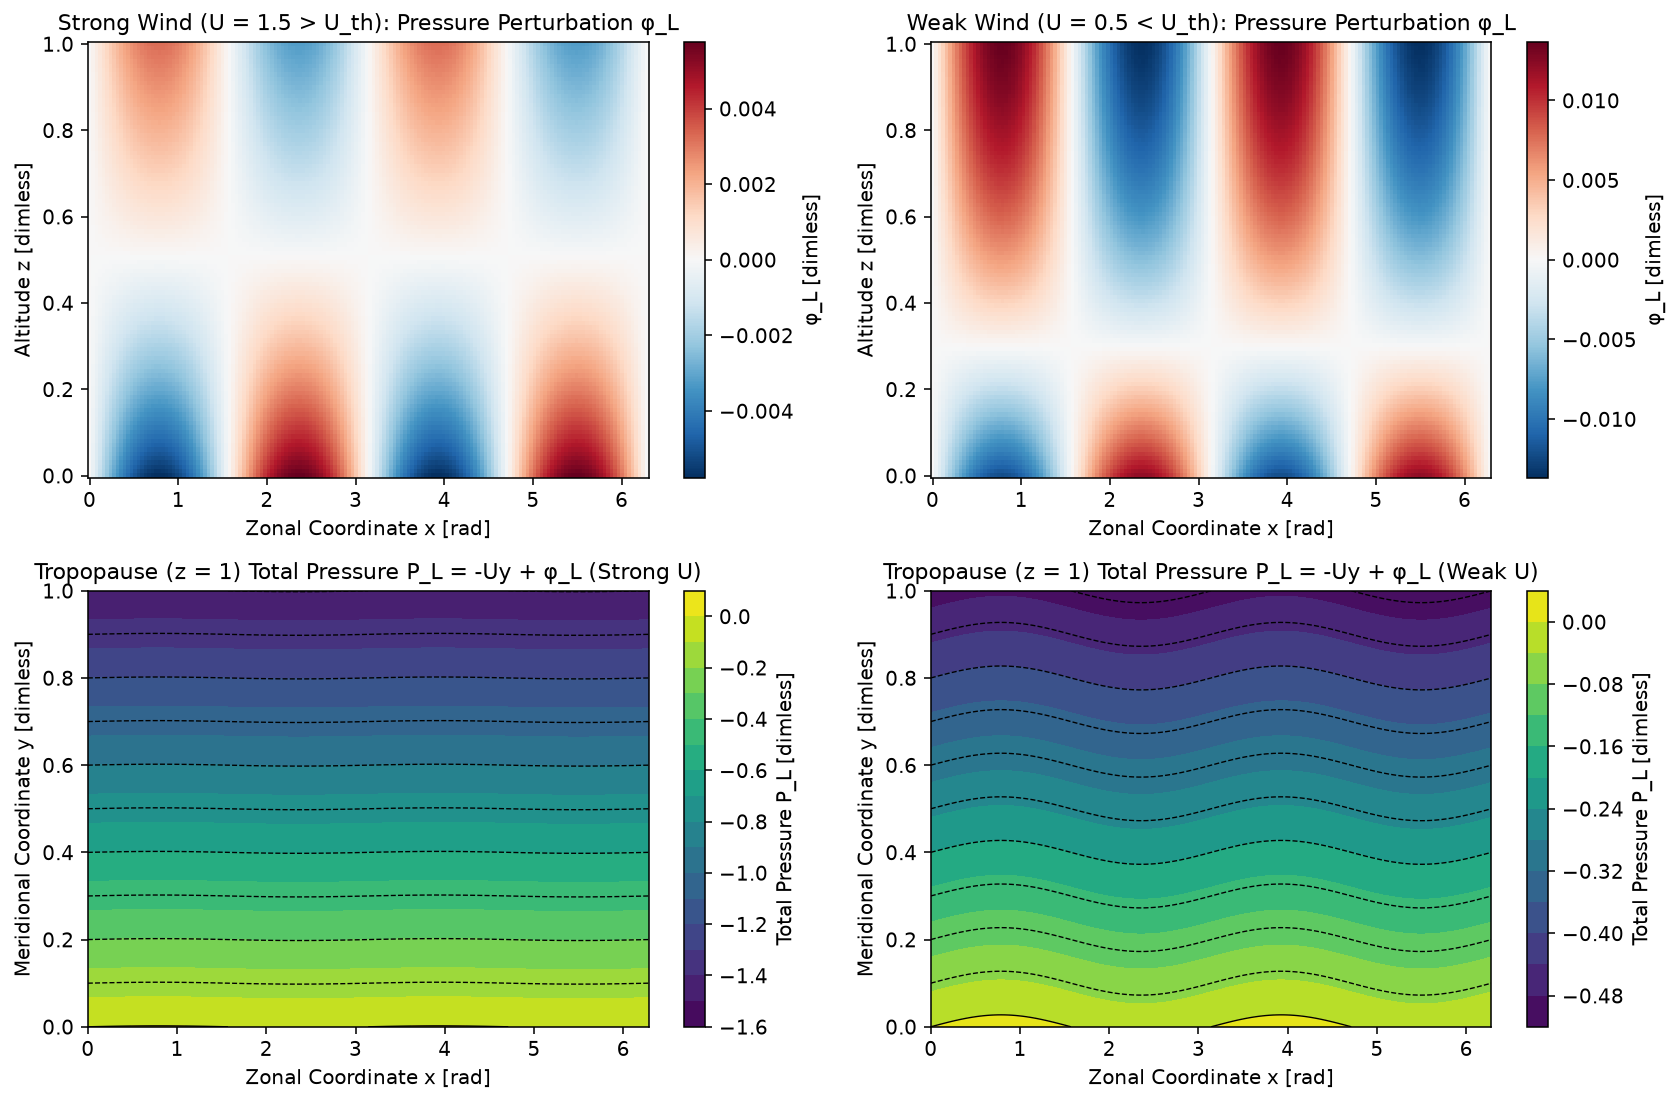

In [18]:
# Top row: vertical cross-sections of phi_L; bottom row: lid pressure contours
fig, axes = plt.subplots(2, 2, figsize=(12.2, 8.0))

im0 = axes[0, 0].pcolormesh(Xl_s, Zl_s, phil_s, shading="auto", cmap="RdBu_r")
axes[0, 0].set_title(f"Strong Wind (U = {p_strong['U']} > U_th): Pressure Perturbation φ_L")
axes[0, 0].set_xlabel("Zonal Coordinate x [rad]")
axes[0, 0].set_ylabel("Altitude z [dimless]")
plt.colorbar(im0, ax=axes[0, 0], label="φ_L [dimless]")

im1 = axes[0, 1].pcolormesh(Xl_w, Zl_w, phil_w, shading="auto", cmap="RdBu_r")
axes[0, 1].set_title(f"Weak Wind (U = {p_weak['U']} < U_th): Pressure Perturbation φ_L")
axes[0, 1].set_xlabel("Zonal Coordinate x [rad]")
axes[0, 1].set_ylabel("Altitude z [dimless]")
plt.colorbar(im1, ax=axes[0, 1], label="φ_L [dimless]")

c0 = axes[1, 0].contourf(XX_y, YY_y, P_top_strong, levels=16, cmap="viridis")
axes[1, 0].contour(XX_y, YY_y, P_top_strong, levels=10, colors="k", linewidths=0.7)
axes[1, 0].set_title("Tropopause (z = 1) Total Pressure P_L = -Uy + φ_L (Strong U)")
axes[1, 0].set_xlabel("Zonal Coordinate x [rad]")
axes[1, 0].set_ylabel("Meridional Coordinate y [dimless]")
plt.colorbar(c0, ax=axes[1, 0], label="Total Pressure P_L [dimless]")

c1 = axes[1, 1].contourf(XX_y, YY_y, P_top_weak, levels=16, cmap="viridis")
axes[1, 1].contour(XX_y, YY_y, P_top_weak, levels=10, colors="k", linewidths=0.7)
axes[1, 1].set_title("Tropopause (z = 1) Total Pressure P_L = -Uy + φ_L (Weak U)")
axes[1, 1].set_xlabel("Zonal Coordinate x [rad]")
axes[1, 1].set_ylabel("Meridional Coordinate y [dimless]")
plt.colorbar(c1, ax=axes[1, 1], label="Total Pressure P_L [dimless]")

plt.tight_layout()
plt.show()

### Figure 2: Wave Shapes Across Various Wind Patterns & Near our Boundary Conditions

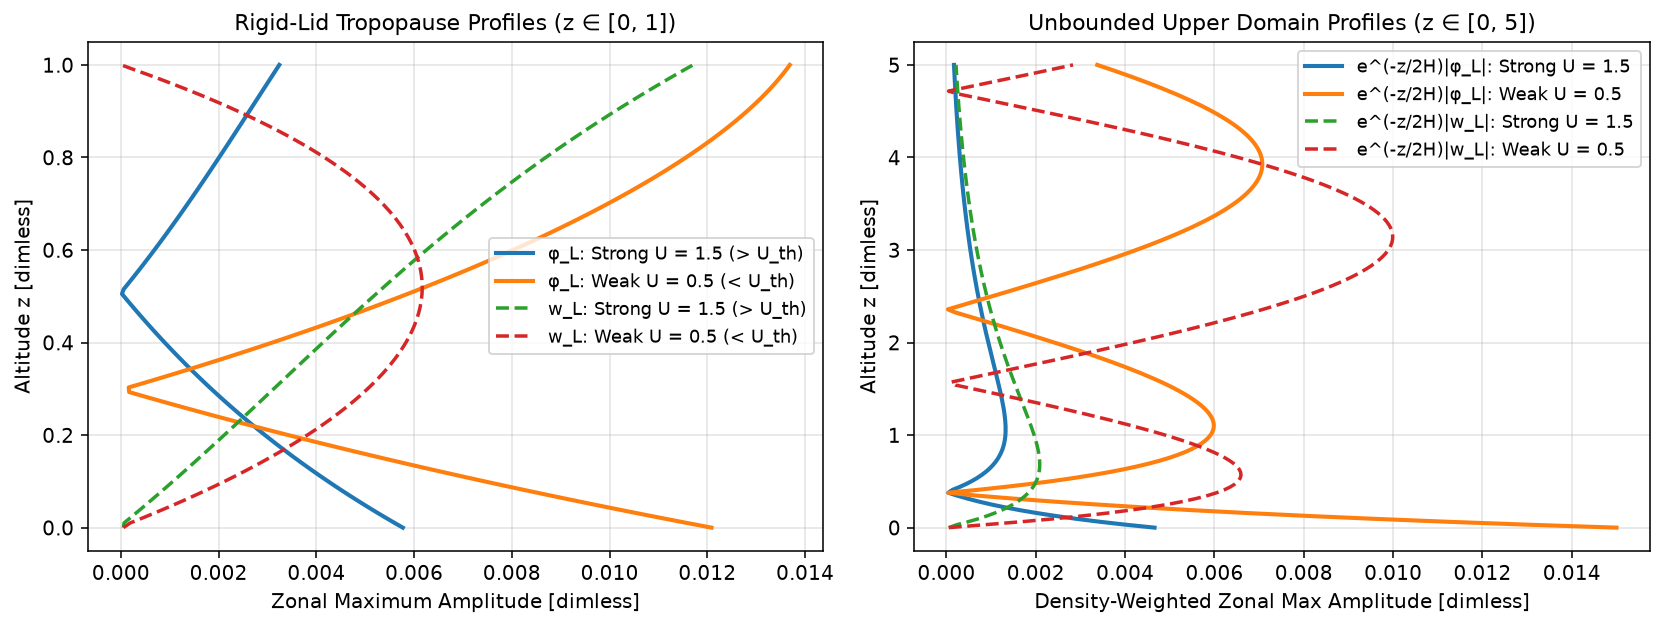

In [19]:
# Compare raw amplitudes on the rigid lid vs. density-weighted amplitudes aloft
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.6))

# Left: rigid-lid vertical profiles
axes[0].plot(np.max(np.abs(phil_s), axis=0), z_lid, lw=2.1, label="φ_L: Strong U = 1.5 (> U_th)")
axes[0].plot(np.max(np.abs(phil_w), axis=0), z_lid, lw=2.1, label="φ_L: Weak U = 0.5 (< U_th)")
axes[0].plot(np.max(np.abs(wl_s), axis=0), z_lid, "--", lw=1.8, label="w_L: Strong U = 1.5 (> U_th)")
axes[0].plot(np.max(np.abs(wl_w), axis=0), z_lid, "--", lw=1.8, label="w_L: Weak U = 0.5 (< U_th)")
axes[0].set_xlabel("Zonal Maximum Amplitude [dimless]")
axes[0].set_ylabel("Altitude z [dimless]")
axes[0].set_title("Rigid-Lid Tropopause Profiles (z ∈ [0, 1])")
axes[0].grid(True, alpha=0.35)
axes[0].legend()

# Right: factor out exp(z/2H) growth so we see true wave behavior
comp_unb = np.exp(-z_unb / (2.0 * p_weak["H"]))
axes[1].plot(np.max(np.abs(phiu_s * comp_unb[None, :]), axis=0), z_unb, lw=2.1, label="e^(-z/2H)|φ_L|: Strong U = 1.5")
axes[1].plot(np.max(np.abs(phiu_w * comp_unb[None, :]), axis=0), z_unb, lw=2.1, label="e^(-z/2H)|φ_L|: Weak U = 0.5")
axes[1].plot(np.max(np.abs(wu_s * comp_unb[None, :]), axis=0), z_unb, "--", lw=1.8, label="e^(-z/2H)|w_L|: Strong U = 1.5")
axes[1].plot(np.max(np.abs(wu_w * comp_unb[None, :]), axis=0), z_unb, "--", lw=1.8, label="e^(-z/2H)|w_L|: Weak U = 0.5")
axes[1].set_xlabel("Density-Weighted Zonal Max Amplitude [dimless]")
axes[1].set_ylabel("Altitude z [dimless]")
axes[1].set_title("Unbounded Upper Domain Profiles (z ∈ [0, 5])")
axes[1].grid(True, alpha=0.35)
axes[1].legend()

plt.tight_layout()
plt.show()

### Figure 3: Comparing our 3 Methods

In [20]:
# Pick x = pi/4 where F(x) hits a peak, then use a coarse grid to expose error
z_coarse = np.linspace(0.0, 3.0, 25)
x_peak = np.array([np.pi / 4.0])

_, _, _, _, _, phi_exact_c = solve_field_numerical(x_peak, z_coarse, p_weak, "unbounded", "rk4")
_, _, phi_fe_c, _, _, _ = solve_field_numerical(x_peak, z_coarse, p_weak, "unbounded", "fe")
_, _, phi_be_c, _, _, _ = solve_field_numerical(x_peak, z_coarse, p_weak, "unbounded", "be")
_, _, phi_rk4_c, _, _, _ = solve_field_numerical(x_peak, z_coarse, p_weak, "unbounded", "rk4")

# Near-exact reference on a fine grid
z_dense = np.linspace(0.0, 3.0, 400)
_, _, phi_dense_ref, _, _, _ = solve_field_numerical(x_peak, z_dense, p_weak, "unbounded", "rk4")

In [21]:
# Halve dz repeatedly to demonstrate linear vs log reduction in error between methods
nz_sweep = [25, 50, 100, 200, 400]
dz_arr, err_fe, err_be, err_rk4 = [], [], [], []
for nzi in nz_sweep:
    zi = np.linspace(0.0, 3.0, nzi)
    dz_arr.append(zi[1] - zi[0])
    _, _, p_fe, _, _, p_ex = solve_field_numerical(x_peak, zi, p_weak, "unbounded", "fe")
    _, _, p_be, _, _, _ = solve_field_numerical(x_peak, zi, p_weak, "unbounded", "be")
    _, _, p_rk, _, _, _ = solve_field_numerical(x_peak, zi, p_weak, "unbounded", "rk4")
    err_fe.append(np.sqrt(np.mean((p_fe - p_ex) ** 2)))
    err_be.append(np.sqrt(np.mean((p_be - p_ex) ** 2)))
    err_rk4.append(np.sqrt(np.mean((p_rk - p_ex) ** 2)))

dz_arr = np.array(dz_arr)

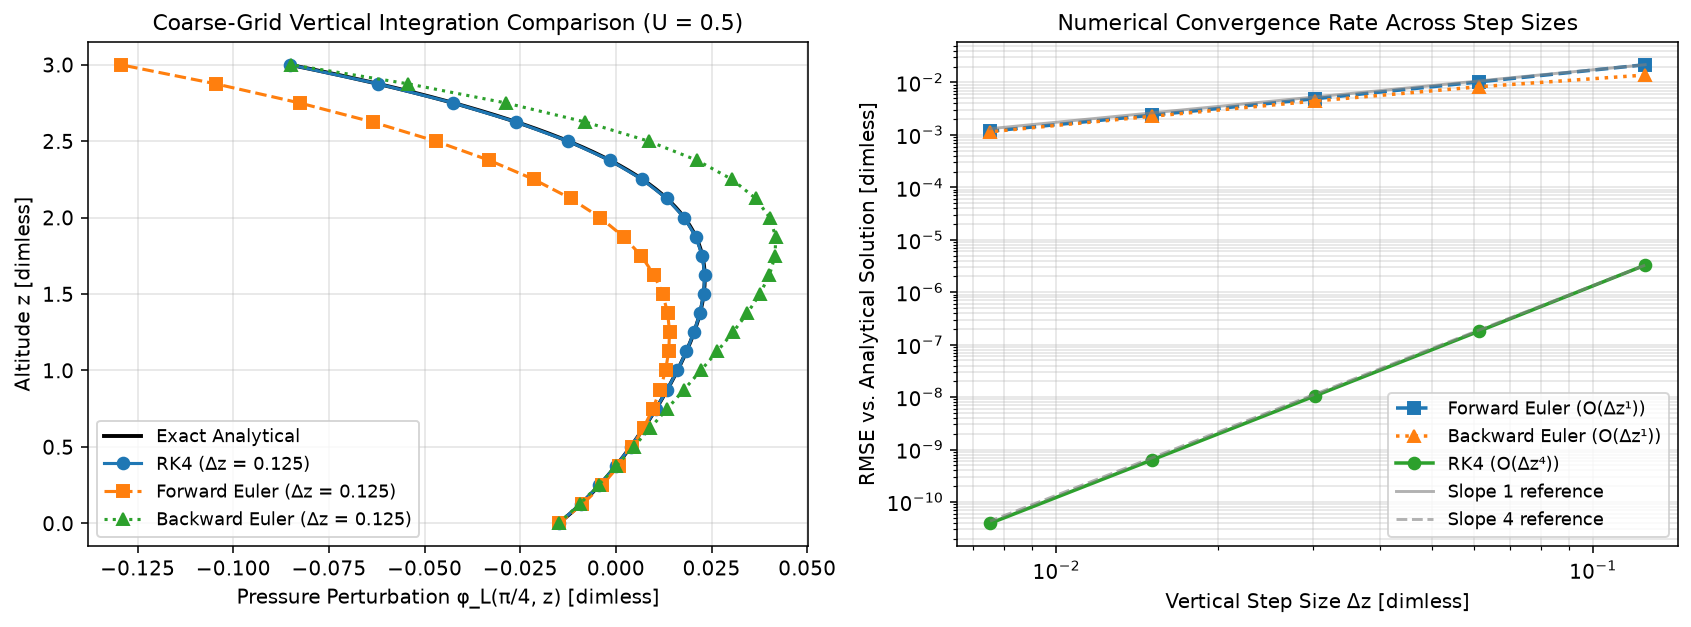

In [22]:
# Left: coarse profile accuracy; right: log-log convergence vs. slope-1 and slope-4 guides
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6))

axes[0].plot(phi_dense_ref[0], z_dense, "k-", lw=2.0, label="Exact Analytical")
axes[0].plot(phi_rk4_c[0], z_coarse, "o-", lw=1.6, label="RK4 (Δz = 0.125)")
axes[0].plot(phi_fe_c[0], z_coarse, "s--", lw=1.6, label="Forward Euler (Δz = 0.125)")
axes[0].plot(phi_be_c[0], z_coarse, "^:", lw=1.6, label="Backward Euler (Δz = 0.125)")
axes[0].set_xlabel("Pressure Perturbation φ_L(π/4, z) [dimless]")
axes[0].set_ylabel("Altitude z [dimless]")
axes[0].set_title("Coarse-Grid Vertical Integration Comparison (U = 0.5)")
axes[0].grid(True, alpha=0.35)
axes[0].legend()

axes[1].loglog(dz_arr, err_fe, "s--", lw=1.8, label="Forward Euler (O(Δz¹))")
axes[1].loglog(dz_arr, err_be, "^:", lw=1.8, label="Backward Euler (O(Δz¹))")
axes[1].loglog(dz_arr, err_rk4, "o-", lw=1.8, label="RK4 (O(Δz⁴))")
axes[1].loglog(dz_arr, err_fe[0] * (dz_arr / dz_arr[0]) ** 1, "-", color="0.5", alpha=0.6, label="Slope 1 reference")
axes[1].loglog(dz_arr, err_rk4[0] * (dz_arr / dz_arr[0]) ** 4, "--", color="0.5", alpha=0.6, label="Slope 4 reference")
axes[1].set_xlabel("Vertical Step Size Δz [dimless]")
axes[1].set_ylabel("RMSE vs. Analytical Solution [dimless]")
axes[1].set_title("Numerical Convergence Rate Across Step Sizes")
axes[1].grid(True, which="both", alpha=0.35)
axes[1].legend()

plt.tight_layout()
plt.show()

### Figure 4: Sensitivity of the Zonal Wind & Static Stability

In [23]:
# Sweep U across both regimes for two stabilities and measure upper-level amplitude at z = 5
U_vals = np.linspace(0.3, 2.2, 45)
S_cases = [1.0, 1.35]
colors = ["#1f77b4", "#d95f02"]

sweep_results = []
for idx_s, S_val in enumerate(S_cases):
    top_amps = []
    U_thresh_case = 4.0 * (0.5**2) * 1.0 * S_val
    for u_val in U_vals:
        pu = make_params(U=u_val, S=S_val)
        _, _, phi_u, _, _, _ = solve_field_numerical(x_grid, z_unb, pu, "unbounded", "rk4")
        # Density-weighted amplitude at z = 5
        amp_top = np.max(np.abs(phi_u[:, -1] * np.exp(-5.0 / (2.0 * pu["H"]))))
        top_amps.append(amp_top)
    sweep_results.append((S_val, U_thresh_case, top_amps, colors[idx_s]))

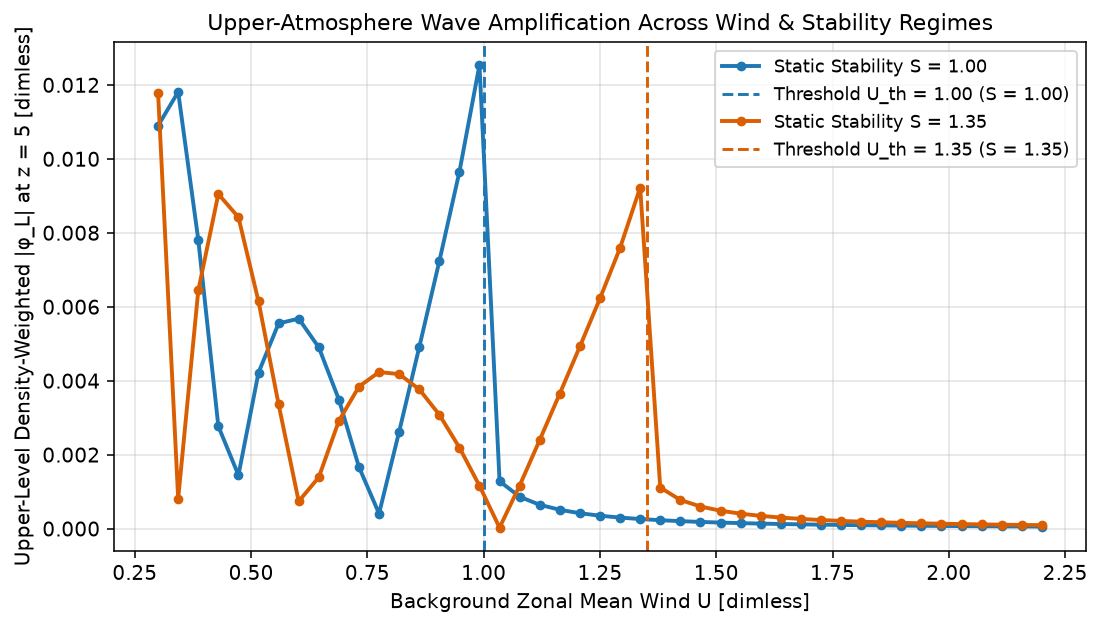

In [24]:
# Plot the sweep curves with dashed vertical lines marking each U_th threshold
fig, ax = plt.subplots(figsize=(8.0, 4.6))

for S_val, U_thresh_case, top_amps, color in sweep_results:
    ax.plot(U_vals, top_amps, "o-", markersize=4, color=color, lw=2.0,
            label=f"Static Stability S = {S_val:.2f}")
    ax.axvline(U_thresh_case, color=color, linestyle="--", lw=1.5,
               label=f"Threshold U_th = {U_thresh_case:.2f} (S = {S_val:.2f})")

ax.set_xlabel("Background Zonal Mean Wind U [dimless]")
ax.set_ylabel("Upper-Level Density-Weighted |φ_L| at z = 5 [dimless]")
ax.set_title("Upper-Atmosphere Wave Amplification Across Wind & Stability Regimes")
ax.grid(True, alpha=0.35)
ax.legend()
plt.tight_layout()
plt.show()

### Potential Alternate Method of Computing Figure 4
#### MORE TESTING YAY

In [25]:
# Vectorized across x so we stop making Python loop over 160 columns every single step
def ode_rhs_z(z_val, state, F_x, p):
    ## First-order system d/dz [phi_L, d(phi_L)/dz] from Eq. (6) for scalar or 1D F_x.
    y1, y2 = state
    U, beta_L, S, H, k_s, Q0 = p["U"], p["beta_L"], p["S"], p["H"], p["k_s"], p["Q0"]
    forcing = -(k_s + 1.0 / H) * (Q0 / U) * F_x * np.exp(-k_s * z_val)
    dy1 = y2
    dy2 = (1.0 / H) * y2 - (beta_L * S / U) * y1 + forcing
    return np.stack([dy1, dy2], axis=0)


def solve_vertical_ivp(z, y0, F_x, p, method="rk4"):
    ## Integrate [phi_L, d(phi_L)/dz] along z across all x columns at once.
    ## y0 has shape (2,) for a single column or (2, nx) for nx columns.
    F_arr = np.asarray(F_x, dtype=float)
    y0_arr = np.asarray(y0, dtype=float)
    col_shape = np.broadcast_shapes(F_arr.shape, y0_arr.shape[1:])

    nz = len(z)
    sol = np.zeros((nz, 2) + col_shape, dtype=float)
    sol[0] = np.broadcast_to(y0_arr, (2,) + col_shape)
    F_bcast = np.broadcast_to(F_arr, col_shape)

    U, beta_L, S, H, k_s, Q0 = p["U"], p["beta_L"], p["S"], p["H"], p["k_s"], p["Q0"]
    a21 = -(beta_L * S) / U
    a22 = 1.0 / H

    for j in range(nz - 1):
        zc, zn = z[j], z[j + 1]
        dz = zn - zc
        yc = sol[j]

        if method == "fe":
            sol[j + 1] = yc + dz * ode_rhs_z(zc, yc, F_bcast, p)
        elif method == "be":
            ### Closed-form 2x2 inverse across all columns at once—no per-column linalg.solve needed
            f_next = -(k_s + 1.0 / H) * (Q0 / U) * F_bcast * np.exp(-k_s * zn)
            rhs1 = yc[0] + dz * yc[1]
            rhs2 = yc[1] + dz * (a21 * yc[0] + f_next)
            det = (1.0 - dz * a22) - (dz**2) * a21
            sol[j + 1, 0] = ((1.0 - dz * a22) * rhs1 + dz * rhs2) / det
            sol[j + 1, 1] = (dz * a21 * rhs1 + rhs2) / det
        elif method == "rk4":
            k1 = ode_rhs_z(zc, yc, F_bcast, p)
            k2 = ode_rhs_z(zc + 0.5 * dz, yc + 0.5 * dz * k1, F_bcast, p)
            k3 = ode_rhs_z(zc + 0.5 * dz, yc + 0.5 * dz * k2, F_bcast, p)
            k4 = ode_rhs_z(zn, yc + dz * k3, F_bcast, p)
            sol[j + 1] = yc + (dz / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
        else:
            raise ValueError("method must be 'fe', 'be', or 'rk4'")

    return sol[:, 0], sol[:, 1]

In [26]:
# Keep the old per-column loop around strictly as a speed bump to benchmark against
def solve_field_numerical_loop(x, z, p, bc_type="unbounded", method="rk4"):
    if bc_type == "unbounded":
        X, Z, phi_ref, w_ref, v_ref = analytical_unbounded(x, z, p)
    elif bc_type == "rigid_lid":
        X, Z, phi_ref, w_ref, v_ref = analytical_rigid_lid(x, z, p)
    else:
        raise ValueError("bc_type must be 'unbounded' or 'rigid_lid'")

    G, F = forcing_xz(x, p)
    U, S, Q0, k_s = p["U"], p["S"], p["Q0"], p["k_s"]
    dphi0_dx_int = (Q0 / U) * F

    phi_num = np.zeros_like(phi_ref)
    dphi_dz_num = np.zeros_like(phi_ref)
    for i in range(len(x)):
        y0 = [phi_ref[i, 0], dphi0_dx_int[i]]
        phi_num[i, :], dphi_dz_num[i, :] = solve_vertical_ivp(z, y0, F[i], p, method=method)

    if len(x) > 1:
        dx = x[1] - x[0]
        v_num = np.gradient(phi_num, dx, axis=0)
        d2phi_dxdz = np.gradient(dphi_dz_num, dx, axis=0)
    else:
        v_num = np.zeros_like(phi_num)
        d2phi_dxdz = np.zeros_like(dphi_dz_num)
    w_num = -(U / S) * d2phi_dxdz + (Q0 / S) * G[:, None] * np.exp(-k_s * Z)
    return X, Z, phi_num, w_num, v_num, phi_ref

In [27]:
# Same physics, minus the artisanal per-column Python loop
def solve_field_numerical_vec(x, z, p, bc_type="unbounded", method="rk4"):
    if bc_type == "unbounded":
        X, Z, phi_ref, w_ref, v_ref = analytical_unbounded(x, z, p)
    elif bc_type == "rigid_lid":
        X, Z, phi_ref, w_ref, v_ref = analytical_rigid_lid(x, z, p)
    else:
        raise ValueError("bc_type must be 'unbounded' or 'rigid_lid'")

    G, F = forcing_xz(x, p)
    U, S, Q0, k_s = p["U"], p["S"], p["Q0"], p["k_s"]
    dphi0_dx_int = (Q0 / U) * F

    y0 = np.vstack([phi_ref[:, 0], dphi0_dx_int])
    phi_z_x, dphi_dz_z_x = solve_vertical_ivp(z, y0, F, p, method=method)
    phi_num = phi_z_x.T
    dphi_dz_num = dphi_dz_z_x.T

    if len(x) > 1:
        dx = x[1] - x[0]
        v_num = np.gradient(phi_num, dx, axis=0)
        d2phi_dxdz = np.gradient(dphi_dz_num, dx, axis=0)
    else:
        v_num = np.zeros_like(phi_num)
        d2phi_dxdz = np.zeros_like(dphi_dz_num)
    w_num = -(U / S) * d2phi_dxdz + (Q0 / S) * G[:, None] * np.exp(-k_s * Z)
    return X, Z, phi_num, w_num, v_num, phi_ref

In [ ]:
# Prove they give the same numbers and see how much time we were donating to Python loops
import time

for m in ["fe", "be", "rk4"]:
    _, _, p_loop, w_loop, v_loop, _ = solve_field_numerical_loop(x_grid, z_unb, p_weak, "unbounded", m)
    _, _, p_vec, w_vec, v_vec, _ = solve_field_numerical_vec(x_grid, z_unb, p_weak, "unbounded", m)
    print(
        f"method={m:3s} | max |d_phi|={np.max(np.abs(p_vec - p_loop)):.2e} "
        f"| max |d_w|={np.max(np.abs(w_vec - w_loop)):.2e} "
        f"| max |d_v|={np.max(np.abs(v_vec - v_loop)):.2e}"
    )

U_test = np.linspace(0.3, 2.2, 45)
S_test = [1.0, 1.35]

t0 = time.perf_counter()
for s_val in S_test:
    for u_val in U_test:
        solve_field_numerical_loop(x_grid, z_unb, make_params(U=u_val, S=s_val), "unbounded", "rk4")
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
for s_val in S_test:
    for u_val in U_test:
        solve_field_numerical_vec(x_grid, z_unb, make_params(U=u_val, S=s_val), "unbounded", "rk4")
t_vec = time.perf_counter() - t0

print(f"Loop time (90 runs): {t_loop:.3f} s | Vectorized time (90 runs): {t_vec:.3f} s | Speedup: {t_loop / t_vec:.1f}x")

method=fe  | max |d_phi|=0.00e+00 | max |d_w|=0.00e+00 | max |d_v|=0.00e+00
method=be  | max |d_phi|=0.00e+00 | max |d_w|=0.00e+00 | max |d_v|=0.00e+00
method=rk4 | max |d_phi|=0.00e+00 | max |d_w|=0.00e+00 | max |d_v|=0.00e+00
